# Bogotá: desempleo anual y proyección de enero–marzo de 2027
**Archivo leído:** `bogota_mercado_laboral.xlsx`, hoja `Mercado laboral Bogotá`.
**Cobertura local:** 49 trimestres móviles, desde **enero–marzo de 2022 hasta enero–marzo de 2026**. El último dato termina el **31 de marzo de 2026**.
**Diccionario:** `bogota_metadatos.xlsx`, hoja `Metadata conjunto`.

Se utilizan exclusivamente estos Excel locales. La estimación anual utiliza cuatro trimestres no superpuestos; Ridge utiliza toda la serie de trimestres móviles. No se suman personas entre periodos. Las ventanas móviles se superponen y no son observaciones independientes.

## Preparación y comprobación de columnas
El diccionario y los valores no coinciden en las tres primeras columnas: **Periodo** contiene etiquetas como “ene mar”, **Trimestre** contiene el mes inicial (1–12) y **Trimestre móvil cronológico** contiene el año o rango de años. Renombramos solo la copia en memoria. Para ventanas que cruzan años, usamos el primer año del rango y verificamos el año final.

Los valores de “Tasa de desocupacion” ya están en porcentaje: 8,8 representa 8,8 %. Se contrastan con desocupados / fuerza de trabajo × 100.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore", message="Data Validation extension is not supported and will be removed")
archivo = Path("bogota_mercado_laboral.xlsx")
original = pd.read_excel(archivo, sheet_name="Mercado laboral Bogotá")
metadatos = pd.read_excel("bogota_metadatos.xlsx", sheet_name="Metadata conjunto")
display(metadatos.iloc[:3, :3])
display(original.iloc[[0, 10, 11], :3])
datos = original.dropna(how="all").copy()
datos.columns = [" ".join(c.split()) for c in datos.columns]
datos = datos.rename(columns={"Periodo": "trimestre", "Trimestre": "mes_inicial",
                              "Trimestre móvil cronológico": "periodo_anual"})


,Nombre del Campo,Descripción del campo,Tipo de dato
0,Periodo,Corresponde al año de referencia de la informa...,Númerico
1,Trimestre,Corresponde al trimestre móvil de referencia d...,Texto
2,Trimestre móvil cronológico,Corresponde al número asignado a cada trimestr...,Númerico


,Periodo,Trimestre,Trimestre móvil cronológico
0,ene mar,1,2022
10,nov ene,11,2022 - 2023
11,dic feb,12,2022 - 2023


In [2]:
etiquetas = ["ene mar", "feb abr", "mar may", "abr jun", "may jul", "jun ago",
             "jul sep", "ago oct", "sep nov", "oct dic", "nov ene", "dic feb"]
mes = pd.to_numeric(datos["mes_inicial"], errors="raise")
assert mes.between(1, 12).all() and mes.mod(1).eq(0).all()
assert datos["trimestre"].eq(mes.map(dict(enumerate(etiquetas, 1)))).all()
anios = datos["periodo_anual"].astype(str).str.findall(r"[0-9]{4}")
assert anios.str.len().between(1, 2).all()
datos["inicio"] = pd.to_datetime(dict(year=anios.str[0].astype(int),
                                     month=mes.astype(int), day=1))
datos["fin"] = datos["inicio"] + pd.offsets.MonthEnd(3)
assert datos["fin"].dt.year.eq(anios.str[-1].astype(int)).all()
datos = datos.sort_values("fin").reset_index(drop=True)
assert datos["fin"].is_unique
assert datos["fin"].dt.to_period("M").tolist() == list(
    pd.period_range(datos["fin"].min(), datos["fin"].max(), freq="M"))
campos = ["Desocupados", "Fuerza de trabajo", "Tasa de desocupacion"]
datos[campos] = datos[campos].apply(pd.to_numeric, errors="raise")
assert datos[campos].notna().all().all()
assert datos["Fuerza de trabajo"].gt(0).all()
assert datos["Tasa de desocupacion"].between(0, 100).all()
tasa_calculada = datos["Desocupados"] / datos["Fuerza de trabajo"] * 100
assert np.allclose(datos["Tasa de desocupacion"], tasa_calculada, atol=0.0001)
print("Archivo:", archivo.name)
print("Inicio del primer trimestre:", datos["inicio"].min().date())
print("Fin del último trimestre:", datos["fin"].max().date())
print("Número de trimestres móviles:", len(datos))


Archivo: bogota_mercado_laboral.xlsx
Inicio del primer trimestre: 2022-01-01
Fin del último trimestre: 2026-03-31
Número de trimestres móviles: 49


## 1. Desempleo por año completo
Se seleccionan enero–marzo, abril–junio, julio–septiembre y octubre–diciembre. Cada año debe tener exactamente esas cuatro observaciones. La tasa es **promedio de desocupados / promedio de fuerza de trabajo × 100**; no es el promedio simple de tasas.

El resultado es una **estimación anual construida desde el Excel**, no una tasa anual oficial publicada. Se excluyen los años incompletos.

In [3]:
trimestres = datos.loc[datos["mes_inicial"].isin([1, 4, 7, 10])].copy()
trimestres["año"] = trimestres["inicio"].dt.year
assert not trimestres.duplicated(["año", "mes_inicial"]).any()
completos = trimestres.groupby("año")["mes_inicial"].agg(
    lambda valores: set(valores) == {1, 4, 7, 10})
anios_completos = completos.index[completos]
anual = trimestres.loc[trimestres["año"].isin(anios_completos)].groupby("año")[
    ["Desocupados", "Fuerza de trabajo"]].mean()
anual["Tasa anual estimada (%)"] = anual["Desocupados"] / anual["Fuerza de trabajo"] * 100
assert len(anual) > 0
print("Años excluidos por estar incompletos:", completos.index[~completos].tolist())
display(anual.round(2))


Años excluidos por estar incompletos: [2026]


,Desocupados,Fuerza de trabajo,Tasa anual estimada (%)
año,,,
2022,491404.75,4303901.33,11.42
2023,469927.92,4519753.65,10.40
2024,453629.49,4671596.05,9.71
2025,387149.38,4697766.25,8.24


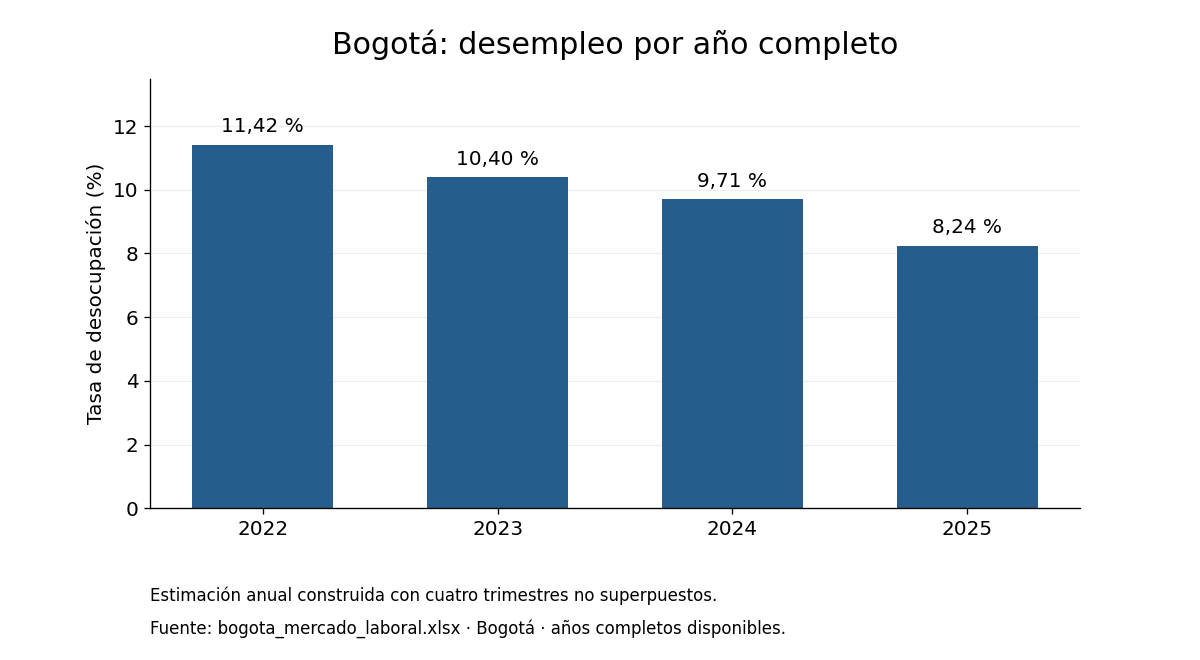

In [4]:
plt.rcParams.update({"font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False})
azul, naranja = "#275D8C", "#C26323"
def porcentaje(valor):
    return f"{valor:.2f} %".replace(".", ",")

fig, eje = plt.subplots(figsize=(10, 5.5))
valores = anual["Tasa anual estimada (%)"]
barras = eje.bar(anual.index.astype(str), valores, color=azul, width=0.6)
eje.bar_label(barras, labels=[porcentaje(v) for v in valores], padding=5)
eje.set_title("Bogotá: desempleo por año completo", fontsize=18, pad=15)
eje.set_ylabel("Tasa de desocupación (%)")
eje.set_ylim(0, valores.max() * 1.18)
eje.grid(axis="y", alpha=0.2)
eje.set_axisbelow(True)
fig.subplots_adjust(bottom=0.23)
fig.text(0.125, 0.09, "Estimación anual construida con cuatro trimestres no superpuestos.", fontsize=10)
fig.text(0.125, 0.04, "Fuente: bogota_mercado_laboral.xlsx · Bogotá · años completos disponibles.", fontsize=10)
plt.show()


## 2. Proyección de enero–marzo de 2027
Ridge combina tasas anteriores con calendario y penaliza coeficientes grandes. Usamos rezagos de **1, 2, 3 y 12 puntos** y seno/coseno del mes final para representar estacionalidad. Fijamos **alpha = 1**, sin ajustarlo con la prueba. El escalado se aprende solo del entrenamiento.

Reservamos los **últimos 12 puntos** como prueba, el mismo horizonte necesario para llegar desde marzo de 2026 hasta marzo de 2027. Entrenamos hasta marzo de 2025 y pronosticamos recursivamente abril de 2025–marzo de 2026. Ningún valor real del bloque de prueba entra en sus predicciones. También comparamos con repetir el último valor de entrenamiento. La muestra de prueba es pequeña; el MAE se expresa en puntos porcentuales.

In [5]:
serie = datos.set_index("fin")["Tasa de desocupacion"]
rezagos = [1, 2, 3, 12]
def variables(historia, fecha):
    return [historia[-r] for r in rezagos] + [
        np.sin(2 * np.pi * fecha.month / 12),
        np.cos(2 * np.pi * fecha.month / 12)]

def entrenar(historia):
    valores = historia.to_numpy()
    X = [variables(valores[:i], historia.index[i]) for i in range(12, len(valores))]
    modelo = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    modelo.fit(X, valores[12:])
    return modelo

def proyectar(modelo, historia, fechas):
    valores = list(historia.to_numpy())
    predicciones = []
    for fecha in fechas:
        valor = float(modelo.predict([variables(valores, fecha)])[0])
        predicciones.append(valor)
        valores.append(valor)
    return np.array(predicciones)


In [6]:
entrenamiento, prueba = serie.iloc[:-12], serie.iloc[-12:]
assert entrenamiento.index.max() < prueba.index.min()
modelo_prueba = entrenar(entrenamiento)
pred_prueba = proyectar(modelo_prueba, entrenamiento, prueba.index)
mae_ridge = mean_absolute_error(prueba, pred_prueba)
mae_base = mean_absolute_error(prueba, np.repeat(entrenamiento.iloc[-1], len(prueba)))
print("Entrenamiento hasta:", entrenamiento.index[-1].date())
print("Prueba:", prueba.index[0].date(), "a", prueba.index[-1].date())
display(pd.DataFrame({"Método": ["Ridge recursiva", "Repetir último valor"],
                      "MAE de prueba (pp)": [mae_ridge, mae_base]}).round(3))


Entrenamiento hasta: 2025-03-31
Prueba: 2025-04-30 a 2026-03-31


,Método,MAE de prueba (pp)
0,Ridge recursiva,1.406
1,Repetir último valor,2.047


In [7]:
# Reajuste con toda la serie, nunca con los promedios anuales.
modelo_final = entrenar(serie)
futuros = pd.period_range(serie.index[-1].to_period("M") + 1, "2027-03", freq="M")
fechas = futuros.to_timestamp("M")
pronostico = pd.DataFrame({"fin": fechas,
                          "tasa estimada (%)": proyectar(modelo_final, serie, fechas)})
pronostico["inicio"] = (futuros - 2).to_timestamp()
assert len(pronostico) == 12
assert pronostico["tasa estimada (%)"].between(0, 100).all()
display(pronostico[["inicio", "fin", "tasa estimada (%)"]].round(2))
estimacion_2027 = pronostico["tasa estimada (%)"].iloc[-1]
primeros = datos.loc[datos["mes_inicial"].eq(1)].copy()
primeros["año"] = primeros["inicio"].dt.year
assert primeros["año"].is_unique
tasa_2026 = primeros.loc[primeros["año"].eq(2026), "Tasa de desocupacion"].item()
cambio = estimacion_2027 - tasa_2026


,inicio,fin,tasa estimada (%)
0,2026-02-01,2026-04-30,8.34
1,2026-03-01,2026-05-31,8.03
2,2026-04-01,2026-06-30,7.74
3,2026-05-01,2026-07-31,7.64
4,2026-06-01,2026-08-31,7.47
5,2026-07-01,2026-09-30,7.37
6,2026-08-01,2026-10-31,7.21
7,2026-09-01,2026-11-30,6.91
8,2026-10-01,2026-12-31,6.59
9,2026-11-01,2027-01-31,6.82


### Enero–marzo: observaciones locales y proyección
Las barras azules son tasas observadas en el Excel para enero–marzo. La barra naranja es la predicción del mismo trimestre de 2027. Los doce pasos intermedios se calculan de forma recursiva: cuando una tasa previa aún no existe, se usa su predicción, no información futura.

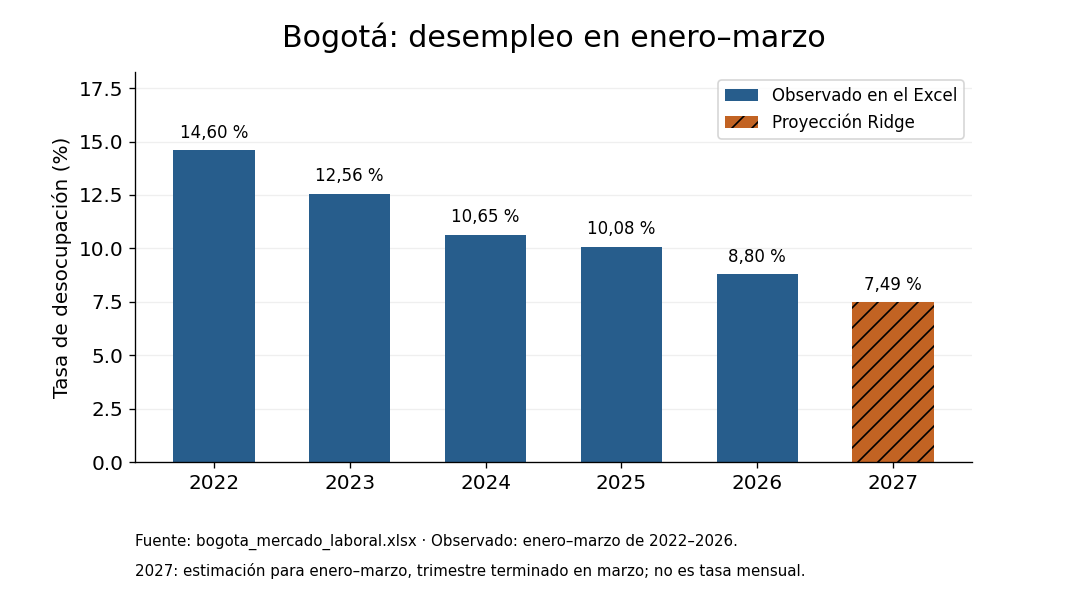

In [8]:
fig, eje = plt.subplots(figsize=(9, 5))
anios = primeros["año"].astype(str).tolist() + ["2027"]
tasas = primeros["Tasa de desocupacion"].tolist() + [estimacion_2027]
barras = eje.bar(anios, tasas, color=[azul] * len(primeros) + [naranja], width=0.6)
barras[-1].set_hatch("//")
eje.bar_label(barras, labels=[porcentaje(v) for v in tasas], padding=5, fontsize=10)
barras[0].set_label("Observado en el Excel")
barras[-1].set_label("Proyección Ridge")
eje.set_title("Bogotá: desempleo en enero–marzo", fontsize=18, pad=15)
eje.set_ylabel("Tasa de desocupación (%)")
eje.set_ylim(0, max(tasas) * 1.25)
eje.legend(fontsize=10, loc="upper right")
eje.grid(axis="y", alpha=0.2)
eje.set_axisbelow(True)
fig.subplots_adjust(bottom=0.23)
fig.text(0.125, 0.09, "Fuente: bogota_mercado_laboral.xlsx · Observado: enero–marzo de 2022–2026.", fontsize=9)
fig.text(0.125, 0.04, "2027: estimación para enero–marzo, trimestre terminado en marzo; no es tasa mensual.", fontsize=9)
plt.show()


In [9]:
direccion = "aumento" if cambio > 0 else "disminución" if cambio < 0 else "cambio"
comparacion = ("Mejora la referencia en esta prueba." if mae_ridge < mae_base else
              "No mejora la referencia en esta prueba; no hay evidencia aquí para preferir Ridge.")
display(Markdown(
    f"**Ridge** es una regresión lineal con penalización: utilizó tasas rezagadas y calendario, "
    f"con los 49 trimestres móviles locales para el reajuste final. "
    f"Su **MAE de prueba fue {mae_ridge:.3f} puntos porcentuales**, frente a "
    f"{mae_base:.3f} al repetir el último valor. {comparacion}" + chr(10) + chr(10) +
    f"Estima que la tasa de enero–marzo pasaría de **{porcentaje(tasa_2026)} en 2026** "
    f"a **{porcentaje(estimacion_2027)} en 2027**: {direccion} de "
    f"**{abs(cambio):.2f} puntos porcentuales**." + chr(10) + chr(10) +
    "**Es una estimación, no una certeza.** La prueba tiene solo 12 puntos correlacionados y "
    "el entrenamiento es corto; los errores recursivos pueden acumularse. No se calcula una banda "
    "de incertidumbre y el MAE no es un intervalo de confianza. No se infieren despidos ni causas."))


**Ridge** es una regresión lineal con penalización: utilizó tasas rezagadas y calendario, con los 49 trimestres móviles locales para el reajuste final. Su **MAE de prueba fue 1.406 puntos porcentuales**, frente a 2.047 al repetir el último valor. Mejora la referencia en esta prueba.

Estima que la tasa de enero–marzo pasaría de **8,80 % en 2026** a **7,49 % en 2027**: disminución de **1.31 puntos porcentuales**.

**Es una estimación, no una certeza.** La prueba tiene solo 12 puntos correlacionados y el entrenamiento es corto; los errores recursivos pueden acumularse. No se calcula una banda de incertidumbre y el MAE no es un intervalo de confianza. No se infieren despidos ni causas.